## Student Retention Project



### Overview

This longitudinal panel dataset is designed to support predictive modeling, risk profiling, and machine learning research focused on higher-education student retention.

It contains 79,239 synthetic semester-level records, tracking students across multiple academic terms for up to 8 semesters. The dataset captures a holistic view of the student experience by combining:

* Demographic information
* Socioeconomic and financial constraints
* Academic performance
* Semester-level progression
* Learning engagement indicators
* Attrition and retention risk factors

The primary objective is to model the probability of future student attrition through the target variable:
`Target_Dropout_Next_Sem`


Data set could be found at: https://www.kaggle.com/datasets/razanihababdellatif/student-retention-and-academic-performance-data

In [14]:
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter
import seaborn as sns
import numpy as np
import scipy
from scipy import stats
import plotly.express as px

### Read data set from CSV

In [15]:
# Read CSV
CSV_PATH = "academic_survival_longitudinal.csv"

df_raw = pd.read_csv(CSV_PATH)
print("Data set shape (rows, cols): ", df_raw.shape)

display(df_raw.head())

Data set shape (rows, cols):  (79239, 22)


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


### Data cleaning and processing

In this section we review the dataset columns and perform any necessary cleaning steps. We display the data types and check for the missing values and do small transformations if that is the case.

In [16]:
# Make a data frame copy to work on it
df = df_raw.copy()

In [17]:
# Display data information
no_rows = df.shape[0]
no_colums = df.shape[1]
print("Number of rows: ", no_rows)
print("Number of columns: ", no_colums, '\n')
print("Dataframe columns and types: ", '\n')
df.dtypes

Number of rows:  79239
Number of columns:  22 

Dataframe columns and types:  



Student_ID                     str
Age                          int64
Gender                         str
First_Generation             int64
Family_Income              float64
Household_Size               int64
Housing_Status                 str
Scholarship                  int64
Tuition_Base                 int64
Semester                     int64
Course_Load                  int64
Work_Hours                 float64
Emergency_Expense          float64
Sem_GPA                    float64
Attendance                 float64
LMS_Logins                 float64
Advising_Visits              int64
Failed_Courses               int64
Financial_Stress           float64
Target_Dropout_Next_Sem      int64
End_of_Semester_Status         str
Censored                     int64
dtype: object

In [18]:
df.describe()

,Age,First_Generation,Family_Income,Household_Size,Scholarship,Tuition_Base,Semester,Course_Load,Work_Hours,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,Censored
count,79239.000000,79239.000000,75635.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000,78372.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239.000000
mean,19.492005,0.327894,61518.384346,3.187547,0.277515,24775.110741,3.145673,14.888615,16.936129,200.496788,2.691463,85.081599,66.375670,0.477530,0.652494,2.578287,0.087293,0.140272
std,2.139140,0.469449,39661.166570,1.332861,0.447775,10794.899387,1.946207,2.307308,10.724479,724.400513,0.422692,6.415864,12.730793,0.671954,0.786066,1.817880,0.282266,0.347271
min,17.000000,0.000000,3000.000000,1.000000,0.000000,15000.000000,1.000000,9.000000,0.000000,0.000000,0.440000,-2.000000,12.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,18.000000,0.000000,35000.000000,2.000000,0.000000,15000.000000,1.000000,12.000000,8.300000,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,19.000000,0.000000,52000.000000,3.000000,0.000000,25000.000000,3.000000,15.000000,16.500000,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,0.000000
75%,21.000000,1.000000,77000.000000,4.000000,1.000000,25000.000000,4.000000,15.000000,24.900000,0.000000,2.960000,89.200000,75.000000,1.000000,1.000000,3.400000,0.000000,0.000000
max,37.000000,1.000000,488000.000000,6.000000,1.000000,45000.000000,8.000000,21.000000,40.000000,3998.000000,3.960000,105.000000,116.000000,3.000000,5.000000,18.600000,1.000000,1.000000


In [19]:
df.describe().T[['min', 'max']]

,min,max
Age,17.00,37.00
First_Generation,0.00,1.00
Family_Income,3000.00,488000.00
Household_Size,1.00,6.00
Scholarship,0.00,1.00
Tuition_Base,15000.00,45000.00
Semester,1.00,8.00
Course_Load,9.00,21.00
Work_Hours,0.00,40.00
Emergency_Expense,0.00,3998.00


Attendance represents the percentage of classes attended. There are some weird values going below 0 and some going over 100, which it basically impossible, so we'll clip that the valid range of numbers.

In [20]:
# Clip attandance values to 0-100 range
out_of_range = (df["Attendance"] < 0) | (df["Attendance"] > 100)
df['Attendance'] = df['Attendance'].clip(0, 100)

In [21]:
# Convert categorical columns to category dtype
categorical_columns = ['Student_ID', 'Gender', 'Housing_Status', 'End_of_Semester_Status']
for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype('category')

display(df.dtypes)

Student_ID                 category
Age                           int64
Gender                     category
First_Generation              int64
Family_Income               float64
Household_Size                int64
Housing_Status             category
Scholarship                   int64
Tuition_Base                  int64
Semester                      int64
Course_Load                   int64
Work_Hours                  float64
Emergency_Expense           float64
Sem_GPA                     float64
Attendance                  float64
LMS_Logins                  float64
Advising_Visits               int64
Failed_Courses                int64
Financial_Stress            float64
Target_Dropout_Next_Sem       int64
End_of_Semester_Status     category
Censored                      int64
dtype: object

In [22]:
# Check for missing values
missing_values = df_raw.isnull().sum()
print("Missing values based on columns: \n")
display(missing_values[missing_values > 0])

#Check for duplicated rows
dup_rows = df.duplicated()
print("Number of duplicated rows:", dup_rows.sum())

Missing values based on columns: 



Family_Income    3604
LMS_Logins        867
dtype: int64

Number of duplicated rows: 0


Family_Income mean:  61518.38434587162
Family_Income median:  52000.0
Family_Income IQ1:  35000.0
Family_Income IQ3:  77000.0
Family_Income IQR:  42000.0
Family Income outliers:  3523


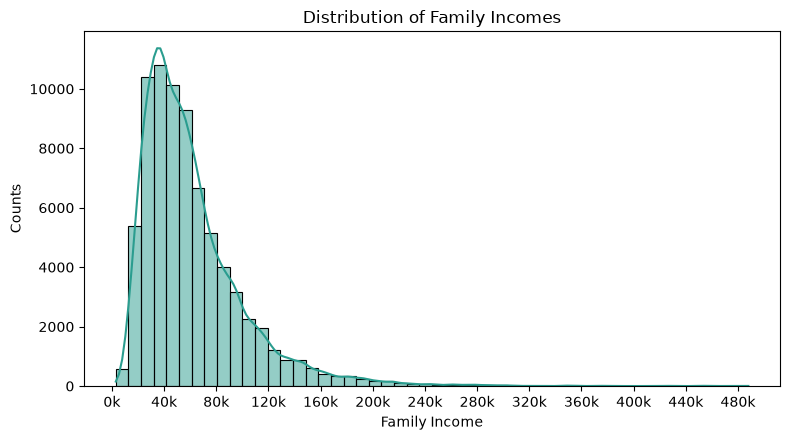

In [23]:
# Check Family Income values
print("Family_Income mean: ", df_raw["Family_Income"].mean())
print("Family_Income median: ", df_raw["Family_Income"].median())
family_income_q1 = df_raw["Family_Income"].quantile(0.25)
family_income_q3 = df_raw["Family_Income"].quantile(0.75)
print("Family_Income IQ1: ", family_income_q1)
print("Family_Income IQ3: ", family_income_q3)
family_income_iqr = family_income_q3 - family_income_q1
print("Family_Income IQR: ", family_income_iqr)

# Check for outliers for family income
family_income_lower_bound = family_income_q1 - 1.5 * family_income_iqr
family_income_upper_bound = family_income_q3 + 1.5 * family_income_iqr

mask = (df_raw["Family_Income"] > family_income_upper_bound) | (df_raw["Family_Income"] < family_income_lower_bound)
n_outliers = mask.sum()
print("Family Income outliers: ", n_outliers)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='Family_Income', bins=50, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of Family Incomes', xlabel='Family Income', ylabel='Counts')
ax.xaxis.set_major_locator(MultipleLocator(40000))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
plt.tight_layout()
plt.show()

For family income there are about 3600 missing value out of the 79,000. Based on the distribution of the values, as seen above, we will use the median value in order to fill the missing data. The median is the perfect choice here because the distribution is right-skewed, because it is robust to the tail and represents a typical family better. The mean would shift a chunk of data upward, as the mean was pulled up due to the long right tail.

In [24]:
# Clean Family_Income missing values

# Add column to flag missing family income
df["Family_Income_Missing"] = df_raw["Family_Income"].isna().astype(int)

display(df[df["Family_Income_Missing"] > 0])
median_family_income = df["Family_Income"].median()
df["Family_Income"] = df["Family_Income"].fillna(median_family_income)
display(df[df["Family_Income_Missing"] > 0])

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing
8,STU_00003,24,Male,1,NaN,3,On-Campus,0,15000,2,...,2.97,87.6,80.0,1,0,1.2,0,Enrolled,0,1
31,STU_00010,20,Male,0,NaN,5,With Parents,0,25000,3,...,2.93,86.1,72.0,0,1,1.0,1,Dropped_Out,0,1
139,STU_00034,18,Male,1,NaN,6,Off-Campus,0,15000,4,...,2.94,88.4,64.0,0,0,2.9,0,Enrolled,0,1
176,STU_00043,24,Female,1,NaN,1,On-Campus,0,25000,4,...,2.09,78.6,57.0,0,4,1.0,1,Dropped_Out,0,1
177,STU_00044,17,Male,0,NaN,5,On-Campus,1,15000,1,...,3.24,91.1,74.0,0,1,1.5,0,Enrolled,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79185,STU_19987,22,Female,0,NaN,3,On-Campus,1,15000,3,...,3.13,84.3,77.0,0,0,1.0,0,Enrolled,1,1
79192,STU_19989,19,Female,1,NaN,4,Off-Campus,0,25000,2,...,2.86,89.8,36.0,0,1,1.0,0,Enrolled,0,1
79204,STU_19991,18,Male,1,NaN,3,Off-Campus,0,15000,4,...,2.49,89.3,53.0,1,0,1.0,0,Enrolled,0,1
79209,STU_19992,24,Male,0,NaN,3,On-Campus,0,25000,4,...,2.79,88.3,55.0,0,2,1.0,0,Enrolled,0,1


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing
8,STU_00003,24,Male,1,52000.0,3,On-Campus,0,15000,2,...,2.97,87.6,80.0,1,0,1.2,0,Enrolled,0,1
31,STU_00010,20,Male,0,52000.0,5,With Parents,0,25000,3,...,2.93,86.1,72.0,0,1,1.0,1,Dropped_Out,0,1
139,STU_00034,18,Male,1,52000.0,6,Off-Campus,0,15000,4,...,2.94,88.4,64.0,0,0,2.9,0,Enrolled,0,1
176,STU_00043,24,Female,1,52000.0,1,On-Campus,0,25000,4,...,2.09,78.6,57.0,0,4,1.0,1,Dropped_Out,0,1
177,STU_00044,17,Male,0,52000.0,5,On-Campus,1,15000,1,...,3.24,91.1,74.0,0,1,1.5,0,Enrolled,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79185,STU_19987,22,Female,0,52000.0,3,On-Campus,1,15000,3,...,3.13,84.3,77.0,0,0,1.0,0,Enrolled,1,1
79192,STU_19989,19,Female,1,52000.0,4,Off-Campus,0,25000,2,...,2.86,89.8,36.0,0,1,1.0,0,Enrolled,0,1
79204,STU_19991,18,Male,1,52000.0,3,Off-Campus,0,15000,4,...,2.49,89.3,53.0,1,0,1.0,0,Enrolled,0,1
79209,STU_19992,24,Male,0,52000.0,3,On-Campus,0,25000,4,...,2.79,88.3,55.0,0,2,1.0,0,Enrolled,0,1


LMS_Login mean:  66.37566988210075
LMS_Login median:  66.0
LMS_Logins outliers:  600


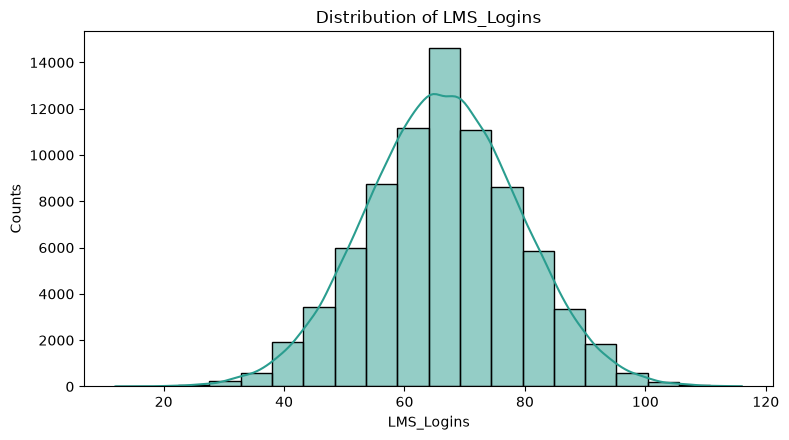

In [25]:
# Check LMS Logins values

print("LMS_Login mean: ", df_raw["LMS_Logins"].mean())
print("LMS_Login median: ", df_raw["LMS_Logins"].median())
lms_logins_q1 = df_raw["LMS_Logins"].quantile(0.25)
lms_logins_q3 = df_raw["LMS_Logins"].quantile(0.75)
lms_logins_iqr = lms_logins_q3 - lms_logins_q1

lms_logins_lower_bound = lms_logins_q1 - 1.5 * lms_logins_iqr
lms_logins_upper_bound = lms_logins_q3 + 1.5 * lms_logins_iqr

mask = (df_raw["LMS_Logins"] > lms_logins_upper_bound) | (df_raw["LMS_Logins"] < lms_logins_lower_bound)
n_outliers = mask.sum()
print("LMS_Logins outliers: ", n_outliers)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='LMS_Logins', bins=20, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of LMS_Logins', xlabel='LMS_Logins', ylabel='Counts')
plt.tight_layout()
plt.show()

LMS Logins values have a normal distribution, also the mean is almost equal to the median. Because it doesnt present a skew-like distribution and the amount of outliers (600) compared to the total number of values (79,000) is low, we'll use the mean value to fill the missing values.

In [26]:
# Clean LMS Logins missing values

# Add column to flag missing LMS Logins
df["LMS_Logins_Missing"] = df_raw["LMS_Logins"].isna().astype(int)

display(df[df["LMS_Logins_Missing"] > 0])
mean_lms_logins = df["LMS_Logins"].mean()
df["LMS_Logins"] = df["LMS_Logins"].fillna(mean_lms_logins)
display(df[df["LMS_Logins_Missing"] > 0])

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing,LMS_Logins_Missing
84,STU_00022,18,Female,0,89000.0,3,With Parents,0,15000,2,...,84.6,NaN,1,0,1.0,0,Enrolled,0,0,1
184,STU_00047,18,Female,0,28000.0,2,On-Campus,0,15000,2,...,86.3,NaN,1,1,5.4,0,Enrolled,0,0,1
271,STU_00075,17,Male,0,55000.0,2,Off-Campus,0,15000,3,...,82.9,NaN,1,0,1.7,0,Enrolled,0,0,1
509,STU_00132,24,Female,0,56000.0,4,Off-Campus,0,25000,3,...,94.9,NaN,0,0,1.0,0,Enrolled,0,0,1
547,STU_00142,18,Female,0,88000.0,2,On-Campus,0,25000,5,...,83.4,NaN,0,2,1.0,0,Enrolled,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78808,STU_19900,19,Female,0,21000.0,3,With Parents,0,25000,2,...,74.2,NaN,1,1,4.8,0,Enrolled,0,0,1
78895,STU_19917,23,Female,0,38000.0,6,On-Campus,1,25000,3,...,68.1,NaN,0,1,6.6,0,Enrolled,0,0,1
78924,STU_19923,19,Male,0,65000.0,4,Off-Campus,0,45000,6,...,85.1,NaN,2,0,2.7,0,Enrolled,0,0,1
79119,STU_19968,19,Female,0,75000.0,5,On-Campus,0,15000,5,...,87.4,NaN,0,1,2.4,0,Enrolled,0,0,1


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,Family_Income_Missing,LMS_Logins_Missing
84,STU_00022,18,Female,0,89000.0,3,With Parents,0,15000,2,...,84.6,66.37567,1,0,1.0,0,Enrolled,0,0,1
184,STU_00047,18,Female,0,28000.0,2,On-Campus,0,15000,2,...,86.3,66.37567,1,1,5.4,0,Enrolled,0,0,1
271,STU_00075,17,Male,0,55000.0,2,Off-Campus,0,15000,3,...,82.9,66.37567,1,0,1.7,0,Enrolled,0,0,1
509,STU_00132,24,Female,0,56000.0,4,Off-Campus,0,25000,3,...,94.9,66.37567,0,0,1.0,0,Enrolled,0,0,1
547,STU_00142,18,Female,0,88000.0,2,On-Campus,0,25000,5,...,83.4,66.37567,0,2,1.0,0,Enrolled,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78808,STU_19900,19,Female,0,21000.0,3,With Parents,0,25000,2,...,74.2,66.37567,1,1,4.8,0,Enrolled,0,0,1
78895,STU_19917,23,Female,0,38000.0,6,On-Campus,1,25000,3,...,68.1,66.37567,0,1,6.6,0,Enrolled,0,0,1
78924,STU_19923,19,Male,0,65000.0,4,Off-Campus,0,45000,6,...,85.1,66.37567,2,0,2.7,0,Enrolled,0,0,1
79119,STU_19968,19,Female,0,75000.0,5,On-Campus,0,15000,5,...,87.4,66.37567,0,1,2.4,0,Enrolled,0,0,1


In [27]:
display(df_raw["Gender"].value_counts())

# Gender values are not consistent
gender_map = {
    'female': 'Female', 'f': 'Female',
    'male': 'Male', 'm': 'Male',
    'other': 'Other',
    'prefer not to say': 'Prefer not to say',
}
df['Gender'] = df_raw['Gender'].str.strip().str.lower().map(gender_map)
display(df['Gender'].value_counts(dropna=False))

Gender
Female               38035
Male                 36556
Other                 1125
female                 875
male                   764
M                      739
F                      716
Prefer not to say      429
Name: count, dtype: int64

Gender
Female               39626
Male                 38059
Other                 1125
Prefer not to say      429
Name: count, dtype: int64

### Exploratory Data Analysis

Now, we have our clean data, we'll perform EDA (Exploratory Data Analysis). We are going to use a various method to visualize the data from multiple perspectives such as demographics, academic performance and financial aspect.

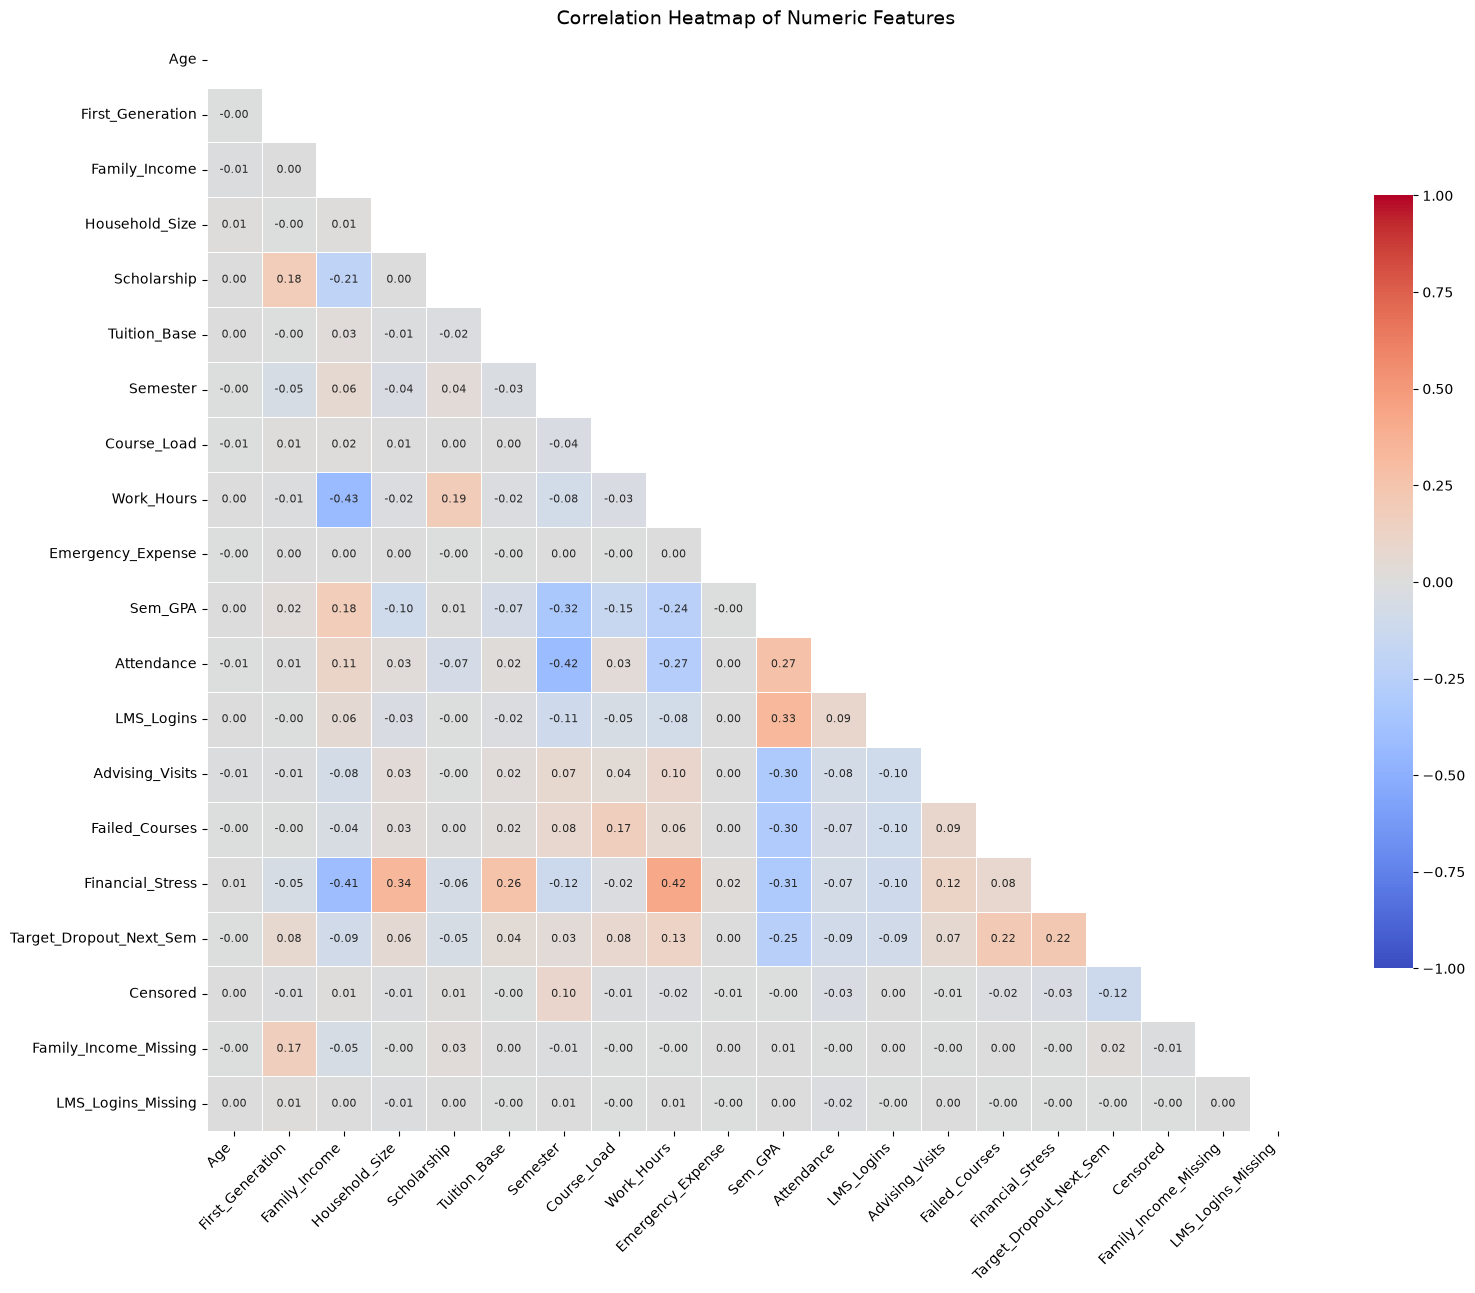

In [28]:
# Select only numeric columns for correlation analysis
numeric_df = df.select_dtypes(include=[np.number])

corr = numeric_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide upper triangle + diagonal

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,                 # display correlation value inside each square
    fmt='.2f',                  # each square contains 2 decimals
    annot_kws={'size': 8},      # size of annotation text
    cmap='coolwarm',
    vmin=-1, vmax=1, center=0,  # white = no correlation, red/blue = strong
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.7},
    ax=ax,
)
ax.set_title('Correlation Heatmap of Numeric Features', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Explanation:
In regards to `Target_Dropout_Next_Sem` the features that more related are the following:
* `Sem_GPA` (r = -0.25) -> lower GPA, more chance to dropout (strongest signal)
* `Failed_Courses` (r = 0.22) -> more courses failed results in more dropout
* `Financial_Stress` (r = 0.22) -> financial pressure matters as much as failures
* `Work_Hours` (r = 0.13) -> more working hours, slightly more dropout

From all of this we can't really say that there is a strongly predictive feature as no there is no |r| > 0.3, but this results in dropout being impacted by multiple factors alltogether instead of a single one.

In [29]:
# Check Person correlation between the most important contributing features to check if any relationship was purely based on luck
r_result = stats.pearsonr(df["Sem_GPA"], df["Target_Dropout_Next_Sem"])
print("Relationship between GPA and dropout -> Pearson r:", round(r_result.statistic, 3), "| p:", round(r_result.pvalue, 5))

r_result = stats.pearsonr(df["Failed_Courses"], df["Target_Dropout_Next_Sem"])
print("Relationship between failed courses and dropout -> Pearson r:", round(r_result.statistic, 3), "| p:", round(r_result.pvalue, 5))

r_result = stats.pearsonr(df["Financial_Stress"], df["Target_Dropout_Next_Sem"])
print("Relationship between financial pressure and dropout -> Pearson r:", round(r_result.statistic, 3), "| p:", round(r_result.pvalue, 5))

r_result = stats.pearsonr(df["Work_Hours"], df["Target_Dropout_Next_Sem"])
print("Relationship between work hours and dropout -> Pearson r:", round(r_result.statistic, 3), "| p:", round(r_result.pvalue, 5))

Relationship between GPA and dropout -> Pearson r: -0.253 | p: 0.0
Relationship between failed courses and dropout -> Pearson r: 0.216 | p: 0.0
Relationship between financial pressure and dropout -> Pearson r: 0.22 | p: 0.0
Relationship between work hours and dropout -> Pearson r: 0.126 | p: 0.0


The`r` values suggest exactly what's inside the correlation heat map, while `p` here is 0, because it's rounded. In fact is not 0, but very small, much smaller that `0.05` which means that it's almost impossible to see a relation this strong between these variables just by pure luck.

In [30]:
# Perform Welch's test on students to stay and on ones who dropout
target = 'Target_Dropout_Next_Sem'
sem1 = df[(df['Semester'] == 1) & (df['Censored'] == 0)]

for col in ['Sem_GPA', 'Failed_Courses', 'Financial_Stress', 'Work_Hours',
            'Attendance', 'Family_Income', 'LMS_Logins']:
    group_a = sem1.loc[sem1[target] == 1, col].dropna().to_numpy()
    group_b = sem1.loc[sem1[target] == 0, col].dropna().to_numpy()

    t_result = stats.ttest_ind(group_a, group_b, equal_var=False)
    print(f"{col:17s} dropout={group_a.mean():9.2f}  stayed={group_b.mean():9.2f}  "
          f"t={t_result.statistic:7.3f}  p={t_result.pvalue:.2e}")

Sem_GPA           dropout=     2.52  stayed=     2.92  t=-31.113  p=3.27e-165
Failed_Courses    dropout=     1.11  stayed=     0.52  t= 22.065  p=3.08e-93
Financial_Stress  dropout=     4.42  stayed=     2.70  t= 20.118  p=2.25e-79
Work_Hours        dropout=    22.01  stayed=    17.54  t= 14.787  p=2.09e-46
Attendance        dropout=    87.69  stayed=    89.22  t= -9.561  p=4.30e-21
Family_Income     dropout= 47044.29  stayed= 59451.13  t=-13.561  p=8.23e-40
LMS_Logins        dropout=    64.98  stayed=    68.60  t=-10.012  p=6.58e-23


The Welch's T-test values displayed above as `t`, how bigger the impact of the specific feature has on dropout case compared to it's uncertainty. For example the GPA gap is 31 times larger than the uncertainty it provides, which means it can't plausibly be by chance.

The sign of the `t` variable gives us the direction, for example in case of: `Sem_GPA`, `Family_Income`, `LMS_Logins` and `Attendance`, if these go up, the dropout rate goes down (negative relationship). But in case of `Failed_Courses`, `Financial_Stress` and `Work_Hours`, as these go up in value, the dropout follows that trajectory (positive relationship).

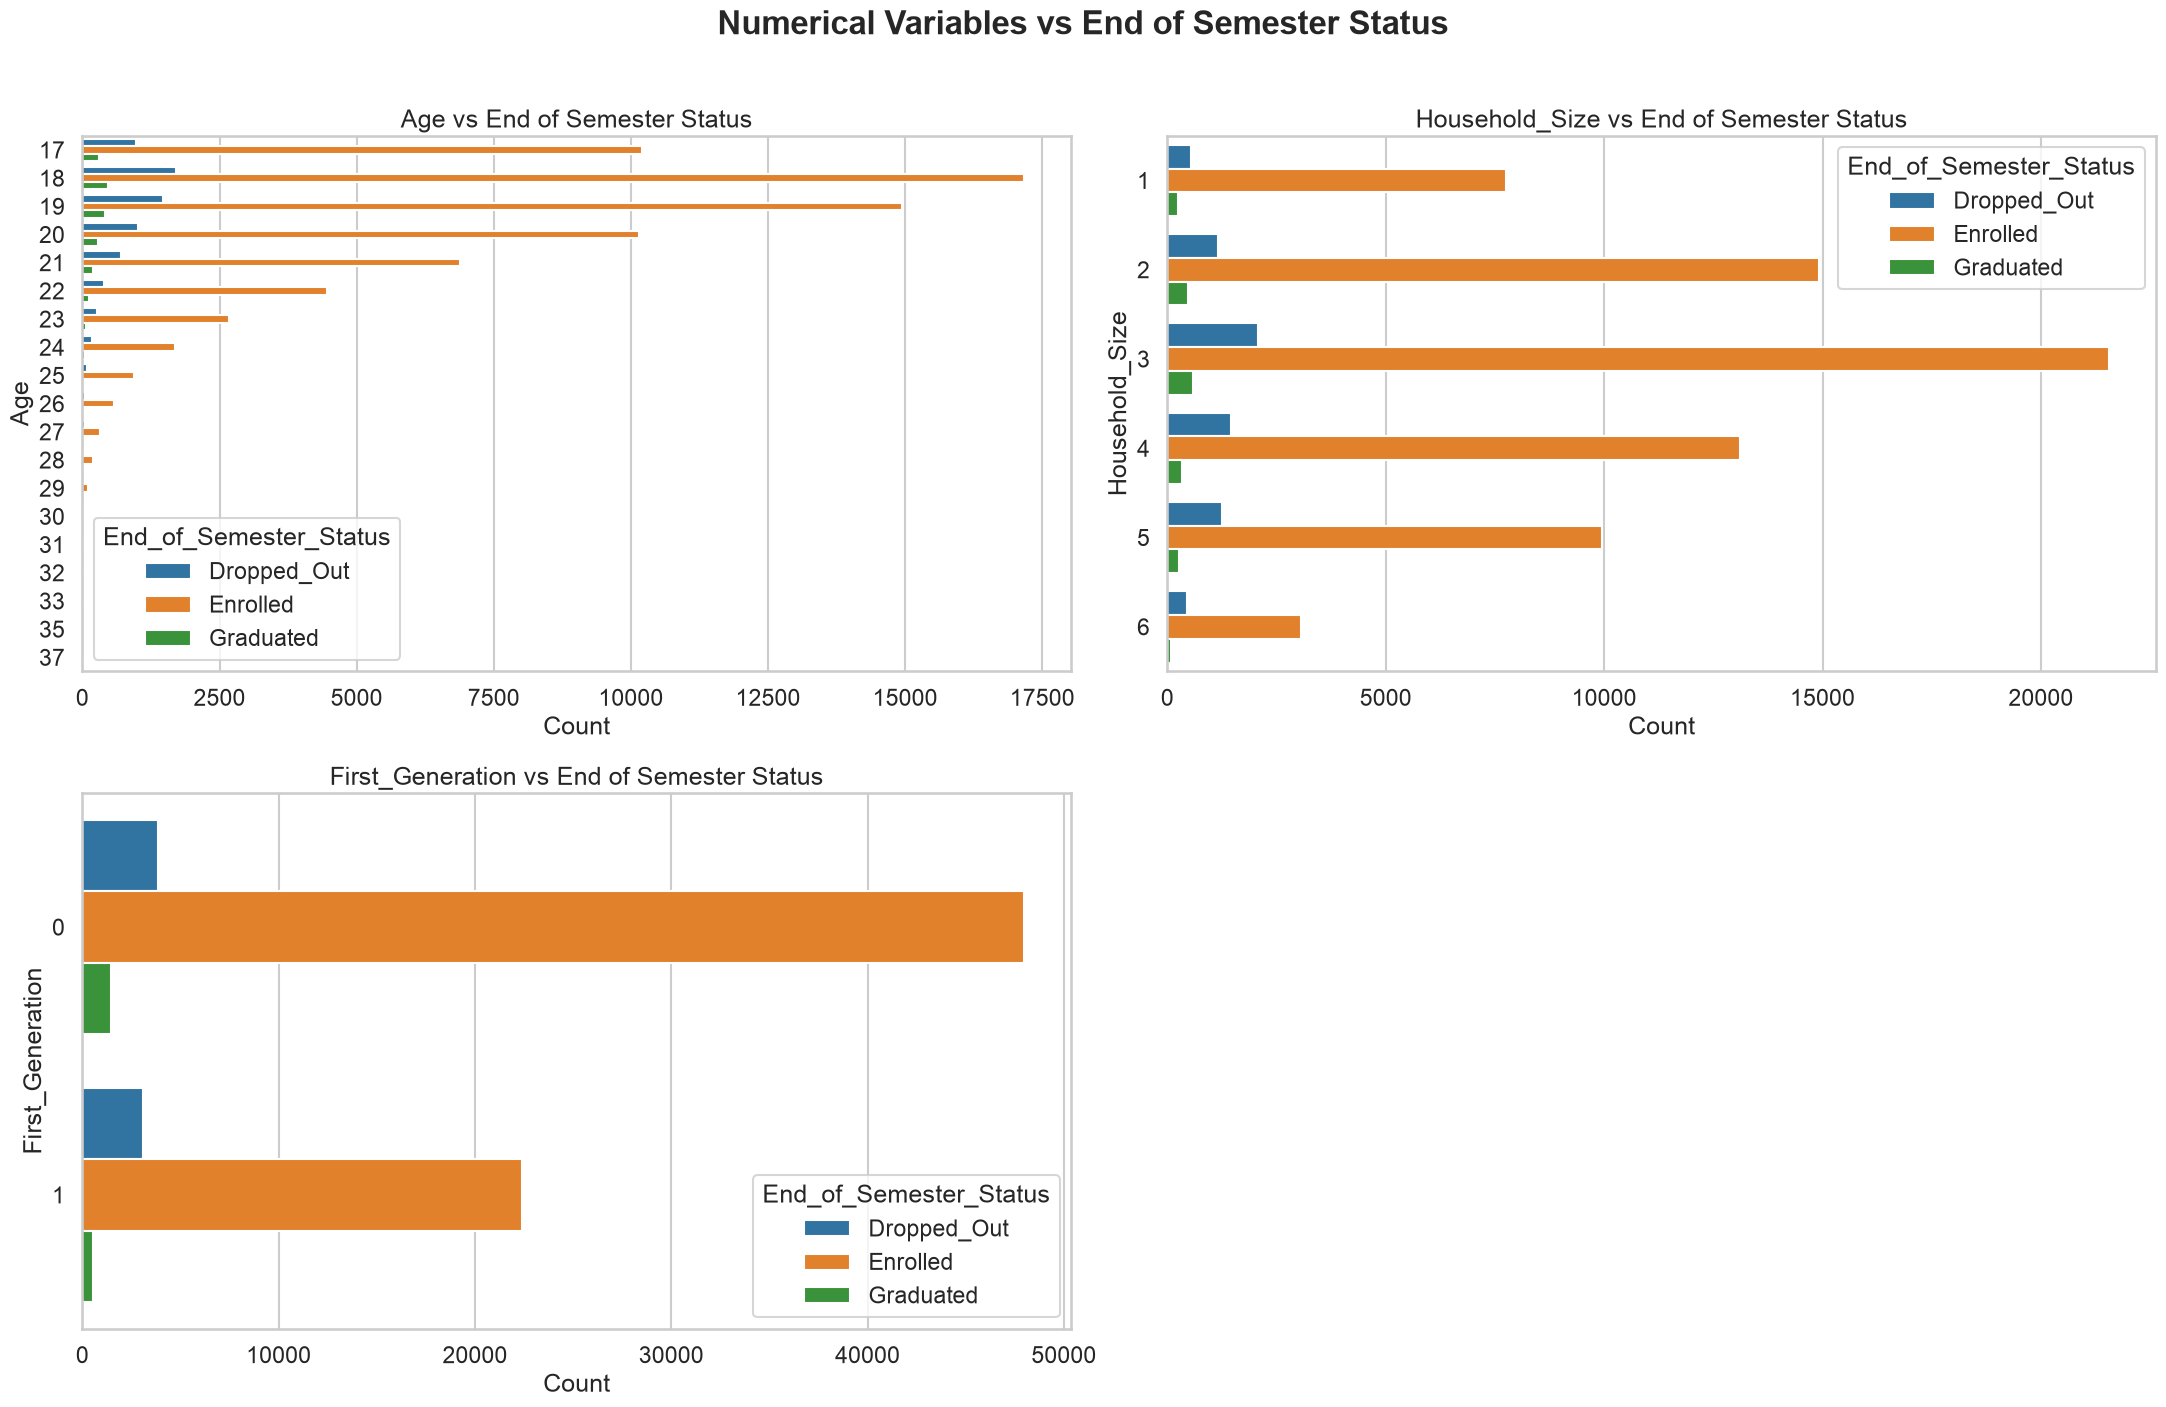

In [31]:
# Display count plots based on demographic, financial and academic performance properties
sns.set_style("whitegrid")
sns.set_context("talk")

# TODO add more columns for financial and academic performance features
num_col = ["Age", "Household_Size", "First_Generation"]

n_cols = 2
n_rows = (len(num_col) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(22, 7 * n_rows)
)

axes = axes.flatten()

# TODO refactor here, i dont like how age is displayed, it's to packed
for i, col in enumerate(num_col):

    sns.countplot(
        data=df,
        y=col,
        hue="End_of_Semester_Status",
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs End of Semester Status")

    axes[i].set_xlabel("Count")
    axes[i].set_ylabel(col)

# Remove unused subplot(s)
for j in range(len(num_col), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Numerical Variables vs End of Semester Status",
    fontsize=24,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# TODO add explanations

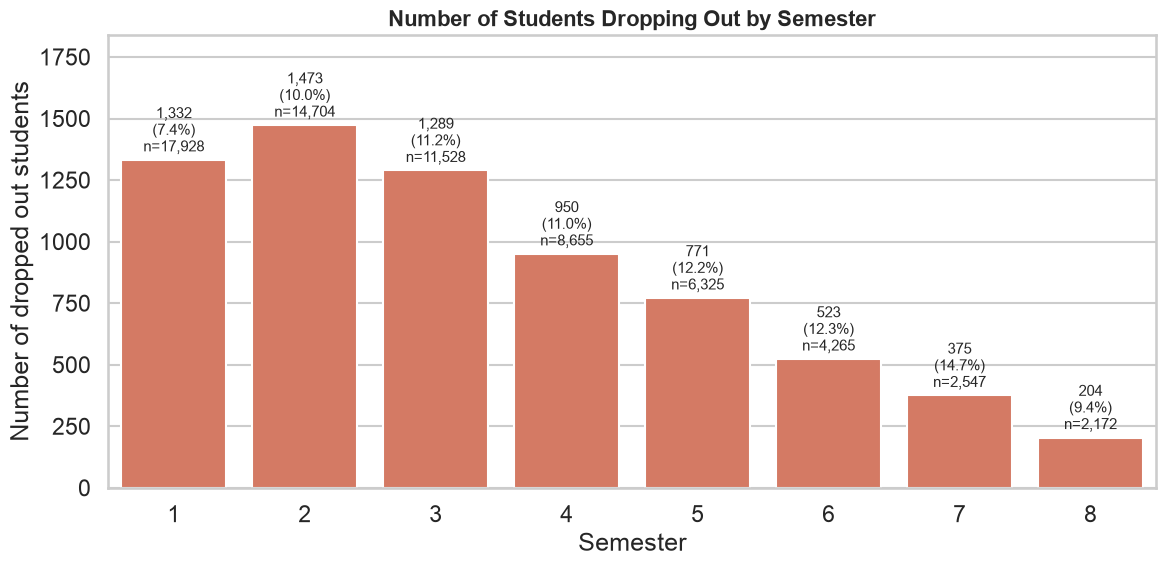

In [32]:
sns.set_style("whitegrid")
sns.set_context("talk")

sem_drop = (
    df[df['Censored'] == 0]
      .groupby('Semester')['Target_Dropout_Next_Sem']
      .agg(dropouts='sum', students='size', dropout_rate='mean')
      .reset_index()
)
sem_drop['dropout_rate'] *= 100

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=sem_drop, x='Semester', y='dropouts', color='#E76F51', ax=ax)

# Label each bar with the dropout count and the rate
labels = [f"{d:,}\n({r:.1f}%)\nn={n:,}"
          for d, r, n in zip(sem_drop['dropouts'], sem_drop['dropout_rate'], sem_drop['students'])]
ax.bar_label(ax.containers[0], labels=labels, fontsize=11, padding=3)

ax.set_title("Number of Students Dropping Out by Semester", fontsize=16, fontweight='bold')
ax.set_xlabel("Semester")
ax.set_ylabel("Number of dropped out students")
ax.set_ylim(0, sem_drop['dropouts'].max() * 1.25)   # make room on top for the bar labels

plt.tight_layout()
plt.show()

The chart shows the most number of students dropping out is in the first three semesters (the second one having the most dropouts). However, the biggest percentage of dropouts is found in 7th semester (375 out of 2,547 , which is around 14.7%). Even with this, the first 3 semesters should be considered high risk, because the number of the students are more important than the percentages, as maybe the data is leaking to keep track until the last semesters. (I don't know if this makes sense, we have to look over it again)

In [33]:
sample = df.sample(frac=0.1, random_state=42)
sample['Failed_Size'] = sample['Failed_Courses'] + 1   # size can't be 0, or the point disappears

fig = px.scatter(
    sample, x='Attendance', y='Sem_GPA',
    color='End_of_Semester_Status', size='Failed_Size',
    hover_data=['Student_ID', 'Semester', 'Failed_Courses', 'Work_Hours', 'Financial_Stress'],
    labels={'Attendance': 'Attendance (%)', 'Sem_GPA': 'Semester GPA',
            'Failed_Size': 'Failed courses (+1)'},
    category_orders={'End_of_Semester_Status': ['Enrolled', 'Dropped_Out', 'Graduated']},
    opacity=0.6,
    title='Interactive GPA and Attendance Explorer',
    template='plotly_white'
)
fig.update_layout(legend_title_text='End of Semester Status')
fig.show()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

The plotly scatter plot shows the Attendace rate vs GPA and the size of the data points is given by the amount of failed courses. We can notice that even high attendance could result in a dropout. Also even a high GPA combined with high attendence and lower failed class could result in a dropout.

Insights:
* If student has low GPA + more than 2-3 failed courses, there is a high probability of dropout
* On the other hand, if student has high GPA, does not fail more than 1-2 courses, but the financial stress is higher, that also increases the risk of dropout.

Usually if the GPA is lower than 2.5, there is high risk of dropout. Most of the samples in this range tend to not continue the next semester.

In [ ]:
gpa = df[df['Censored'] == 0].copy()
gpa['gpa_range'] = pd.cut(gpa['Sem_GPA'], bins=np.arange(0, 4.25, 0.25), labels=np.arange(0.125, 4.0, 0.25))
gpa_dropout = gpa.groupby('gpa_range', observed=True)['Target_Dropout_Next_Sem'].mean().mul(100).reset_index()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(gpa_dropout['gpa_range'].astype(float), gpa_dropout['Target_Dropout_Next_Sem'],
        marker='o', linewidth=2.5, color='#17365D')
ax.set(title='Dropout Percentage by GPA', xlabel='Semester GPA', ylabel='Dropout (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

The line chart between GPA and Dropout rate shows that the percentage of dropouts decreases with the increase of GPA, meaning that there is a negative relationship between GPA and Dropout rate.

In [ ]:
# Compare GPA with observed LMS logins (exclude mean-filled values).
gpa_lms = df.loc[df['LMS_Logins_Missing'] == 0, ['LMS_Logins', 'Sem_GPA']].dropna()
lms_gpa_r = gpa_lms['LMS_Logins'].corr(gpa_lms['Sem_GPA'])

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.regplot(
        data=gpa_lms, x='LMS_Logins', y='Sem_GPA', ci=None,
        scatter_kws={'s': 8, 'alpha': 0.08, 'color': '#2A9D8F', 'edgecolors': 'none'},
        line_kws={'color': '#E76F51', 'linewidth': 2.5, 'label': 'Linear trend'},
        ax=ax,
    )
    ax.set(
        title=f'GPA vs LMS Logins (Pearson r = {lms_gpa_r:.2f})',
        xlabel='LMS logins per semester', ylabel='Semester GPA', ylim=(0, 4),
    )
    ax.legend()
    plt.tight_layout()
    plt.show()

print(f'Observed student-semester records: {len(gpa_lms):,}')
print(f'Pearson correlation: {lms_gpa_r:.3f}')


The correlation between GPA and LMS Logins is approximately 0.33, indicating a moderate positive relationship: semesters with more LMS logins tend to have higher GPAs.

In [ ]:
# Compare GPA distributions across advising visit counts.
gpa_advising = df[['Advising_Visits', 'Sem_GPA']].dropna()
advising_gpa_summary = (
    gpa_advising.groupby('Advising_Visits')['Sem_GPA']
    .agg(records='size', mean_gpa='mean', median_gpa='median')
)
advising_gpa_r = gpa_advising['Advising_Visits'].corr(gpa_advising['Sem_GPA'])

with sns.axes_style('whitegrid'), sns.plotting_context('notebook'):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    sns.boxplot(
        data=gpa_advising, x='Advising_Visits', y='Sem_GPA',
        order=advising_gpa_summary.index.tolist(), color='#2A9D8F', width=0.55,
        flierprops={'markersize': 2, 'alpha': 0.25}, ax=ax,
    )
    ax.scatter(
        np.arange(len(advising_gpa_summary)), advising_gpa_summary['mean_gpa'],
        color='#E76F51', marker='D', s=40, zorder=3, label='Mean GPA',
    )
    ax.set_xticks(np.arange(len(advising_gpa_summary)))
    ax.set_xticklabels([
        f'{visits}\n(n={row.records:,.0f})'
        for visits, row in advising_gpa_summary.iterrows()
    ])
    ax.set(
        title=f'GPA vs Advising Visits (Pearson r = {advising_gpa_r:.2f})',
        xlabel='Advising visits per semester', ylabel='Semester GPA', ylim=(0, 4),
    )
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()

print(f'Pearson correlation: {advising_gpa_r:.3f}')
display(advising_gpa_summary.round(3))


Mean GPA decreases from 2.78 for semesters with no advising visits to 2.60, 2.38, and 2.28 for 1, 2, and 3 visits, respectively. The correlation is approximately −0.30, indicating a moderate negative relationship.
This does not mean advising reduces GPA. One possible explanation is that students who are already struggling seek or are referred for more advising. These data do not establish why the relationship occurs or whether advising improves later outcomes.

In [ ]:
# Relationship between Financial Stress and 4 other features
# Pearson r: close to +1 = both go up together, close to -1 = one goes up while the other goes down, close to 0 = no relationship

features = ['Household_Size', 'Work_Hours', 'Family_Income', 'Sem_GPA']

# Print the correlation for each feature
for col in features:
    data = df[[col, 'Financial_Stress']].dropna()
    if col == 'Family_Income':
        data = df.loc[df['Family_Income_Missing'] == 0, [col, 'Financial_Stress']]  # skip median-filled incomes
    r, p = stats.pearsonr(data[col], data['Financial_Stress'])
    print(f"Financial stress vs {col}: r = {r:.2f}, p = {p:.5f}")

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df_raw, x='Financial_Stress', bins=20, kde=True, color='#2A9D8F', ax=ax)
ax.set(title='Distribution of Financial Stress', xlabel='Financial_Stress', ylabel='Counts')
plt.tight_layout()
plt.show()

In [ ]:
# Check what it would a considered a high financial stress

# Keep only rows where we know what happened next semester
stress = df[df['Censored'] == 0].copy()

# Split the stress group into bins
bins   = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, stress['Financial_Stress'].max()]
labels = ['0-1', '1-2', '2-3', '3-4', '4-5', '5-6', '6-7', '7-8', '8-9', '9-10', '10+']

stress['Stress_Group'] = pd.cut(stress['Financial_Stress'], bins=bins, labels=labels)
stress_dropout = stress.groupby('Stress_Group', observed=True)['Target_Dropout_Next_Sem'].mean() * 100
display(stress_dropout.round(2))

Students with a financial stress less than 3 are generally low risk candidates when it comes to continuing the studies next semester.

Students with a financial stress between 3 and 5 have expose more risk of dropping out (around 15%)

Students with a financial stress over 5 are most inclined to drop out, the rates for each stress level is above 20%. Moreover, as the financial stress goes up, so does the dropout rate (e.g. at financial stress level 8-9, the dropout rate for the next semester is 30%, meaning that 1 in 3 students found in this financial situation will drop out)

In [ ]:
# Plot each relationship
sample = df.sample(frac=0.05, random_state=42)  # use 5% of rows so the scatter plots are readable

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) Household size: average stress for each household size
sns.barplot(data=df, x='Household_Size', y='Financial_Stress', color='#2A9D8F', ax=axes[0, 0])
axes[0, 0].set_title('Financial Stress vs Household Size')

# 2-4) Scatter plot with a trend line
sns.scatterplot(data=sample, x='Work_Hours', y='Financial_Stress',
            ax=axes[0, 1])
axes[0, 1].set_title('Financial Stress vs Work Hours')

sns.scatterplot(data=sample[sample['Family_Income_Missing'] == 0],
            x='Family_Income', y='Financial_Stress',
            ax=axes[1, 0],
            )
axes[1, 0].set_title('Financial Stress vs Family Income')

sns.scatterplot(data=sample, x='Sem_GPA', y='Financial_Stress', ax=axes[1, 1])
axes[1, 1].set_title('Financial Stress vs GPA')

# Trim big income number such as 100.000 to 100k
axes[1, 0].xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x/1000:.0f}k'))

plt.tight_layout()
plt.show()

1. Household size increase financial stress.
2. Work hours also tend to have some candidates being found in the upper parts of the financial stress levels -> at less than 10-20 work hours usually the financial stress is below 4-5, but as the number of worked hours increases, more students appear to be financially struggling.
3. Financial stress is found only in the low family income zone.
4. When the level of financial stress is higher, it seems that the GPA tends to be smaller, but there are also cases of moderate to high financial stress and good GPA(above 3)